In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter

films = pd.read_csv("../data/clean/films.csv")
buzz = pd.read_csv("../data/clean/daily views.csv")
crit = pd.read_csv("../data/clean/critic lines.csv")
shapes = {"Hindi": "o", "Telugu": "s", "Tamil": "^", "Kannada": "D", "Malayalam": "v"}
name = lambda f: f.replace("_2025", "").replace("_", " ").title()
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#dddddd"

def plain_numbers(ax):
    for axis in (ax.xaxis, ax.yaxis):
        f = ScalarFormatter(); f.set_scientific(False)
        axis.set_major_formatter(f); axis.set_minor_formatter(NullFormatter())

def dots(ax, df, x, y):
    for lang, g in df.groupby("language"):
        ax.scatter(g[x], g[y], marker=shapes[lang], s=45, facecolor="white", edgecolor="black", label=lang)
    for _, r in df.iterrows():
        ax.annotate(name(r.film_id), (r[x], r[y]), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.legend(fontsize=8)

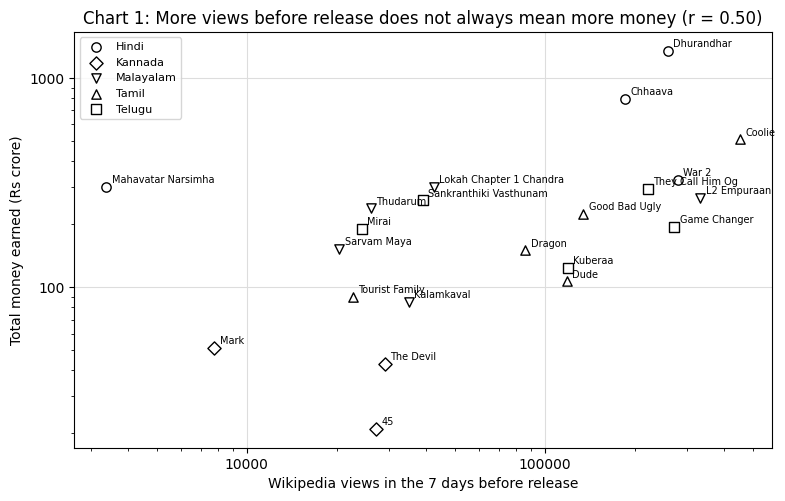

In [2]:
d = films.dropna(subset=["prerelease_views_7d"])
r = np.corrcoef(np.log10(d.prerelease_views_7d), np.log10(d.worldwide_gross_cr))[0, 1]

fig, ax = plt.subplots(figsize=(9, 5.4))
dots(ax, d, "prerelease_views_7d", "worldwide_gross_cr")
ax.set_xscale("log"); ax.set_yscale("log"); plain_numbers(ax)
ax.set_xlabel("Wikipedia views in the 7 days before release")
ax.set_ylabel("Total money earned (Rs crore)")
ax.set_title(f"Chart 1: More views before release does not always mean more money (r = {r:.2f})")
plt.show()

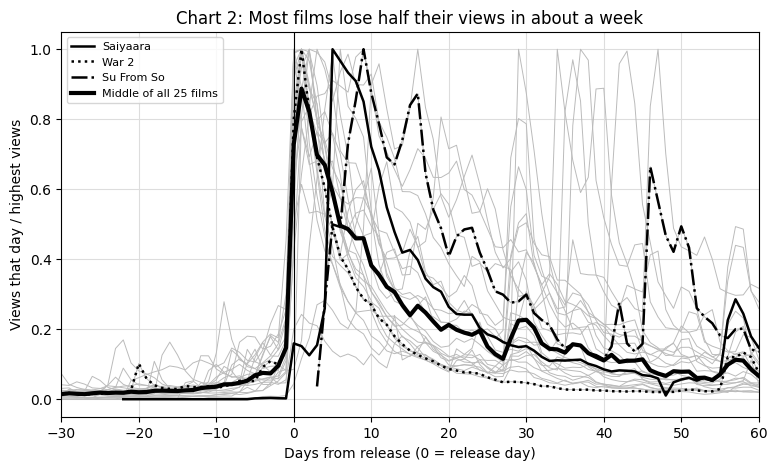

In [3]:
b = buzz.merge(films[["film_id", "peak_views"]], on="film_id")
b["share"] = b.views / b.peak_views

fig, ax = plt.subplots(figsize=(9, 5))
for f, g in b.groupby("film_id"):
    ax.plot(g.day_from_release, g.share, color="#bbbbbb", lw=0.7)
for f, style in [("saiyaara_2025", "-"), ("war_2_2025", ":"), ("su_from_so_2025", "-.")]:
    g = b[b.film_id == f]
    ax.plot(g.day_from_release, g.share, color="black", ls=style, lw=1.8, label=name(f))
middle = b.groupby("day_from_release").share.median()
ax.plot(middle.index, middle.values, color="black", lw=3, label="Middle of all 25 films")
ax.axvline(0, color="black", lw=0.8); ax.set_xlim(-30, 60)
ax.set_xlabel("Days from release (0 = release day)")
ax.set_ylabel("Views that day / highest views")
ax.set_title("Chart 2: Most films lose half their views in about a week")
ax.legend(fontsize=8)
plt.show()

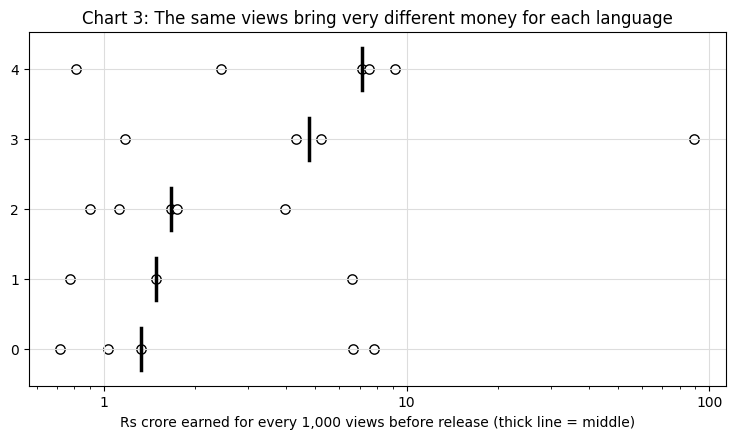

In [4]:
c = films.dropna(subset=["gross_per_1k_prerelease_views"])
order = c.groupby("language").gross_per_1k_prerelease_views.median().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.6))
for i, lang in enumerate(order.index):
    v = c[c.language == lang].gross_per_1k_prerelease_views
    ax.scatter(v, [i] * len(v), facecolor="white", edgecolor="black", s=45)
    ax.plot([v.median()] * 2, [i - 0.3, i + 0.3], color="black", lw=2.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order.index)
ax.set_xscale("log"); plain_numbers(ax)
ax.set_xlabel("Rs crore earned for every 1,000 views before release (thick line = middle)")
ax.set_title("Chart 3: The same views bring very different money for each language")
plt.show()

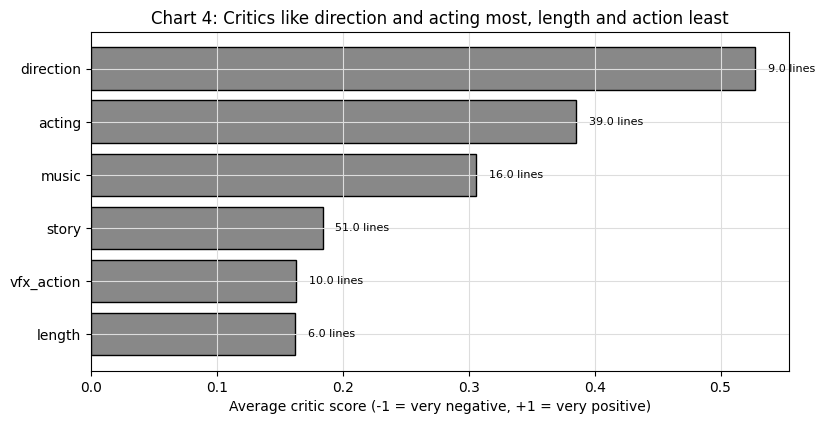

In [5]:
a = crit[crit.aspect != "none"].groupby("aspect").agg(lines=("text", "size"), score=("vader_compound", "mean"))
a = a.sort_values("score")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(a.index, a.score, color="#888888", edgecolor="black")
for i, (topic, row) in enumerate(a.iterrows()):
    ax.text(row.score + 0.01, i, f"{row.lines} lines", va="center", fontsize=8)
ax.set_xlabel("Average critic score (-1 = very negative, +1 = very positive)")
ax.set_title("Chart 4: Critics like direction and acting most, length and action least")
plt.show()

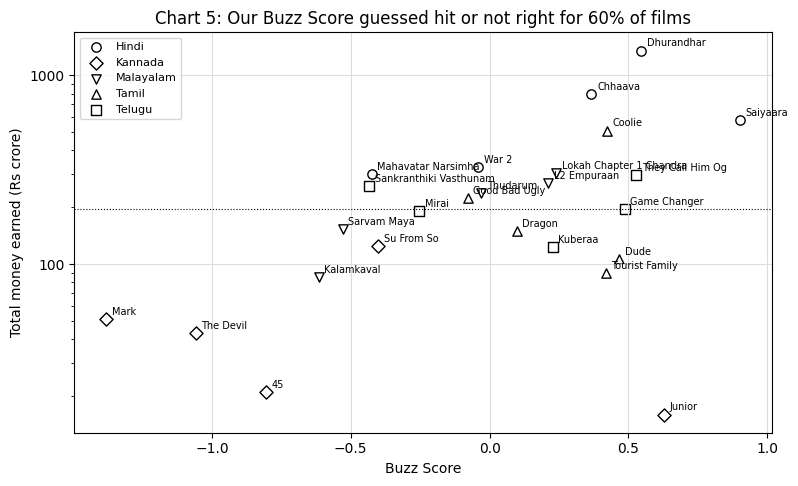

In [6]:
test = pd.read_csv("../outputs/buzz score test.csv")
right = test.called_right.mean()
ok = films.dropna(subset=["buzz_index"])

fig, ax = plt.subplots(figsize=(9, 5.2))
dots(ax, ok, "buzz_index", "worldwide_gross_cr")
ax.set_yscale("log"); plain_numbers(ax)
ax.axhline(ok.worldwide_gross_cr.median(), color="black", ls=":", lw=0.8)
ax.set_xlabel("Buzz Score")
ax.set_ylabel("Total money earned (Rs crore)")
ax.set_title(f"Chart 5: Our Buzz Score guessed hit or not right for {right:.0%} of films")
plt.show()

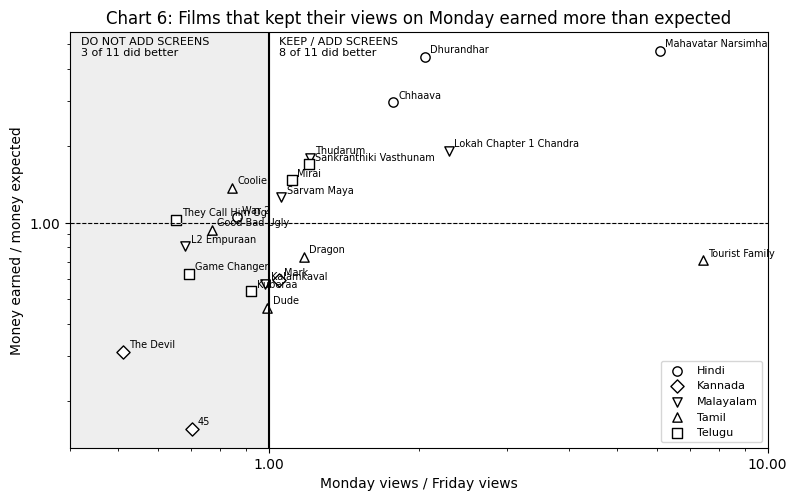

In [7]:
d = films.dropna(subset=["overperformance_x"])
keep = d[d.day3_attention_ratio >= 1]
drop = d[d.day3_attention_ratio < 1]

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.axvspan(0.4, 1, color="#eeeeee")
dots(ax, d, "day3_attention_ratio", "overperformance_x")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.4, 10); plain_numbers(ax)
ax.axhline(1, color="black", ls="--", lw=0.8); ax.axvline(1, color="black")
ax.text(1.05, 4.5, f"KEEP / ADD SCREENS\n{(keep.overperformance_x > 1).sum()} of {len(keep)} did better", fontsize=8)
ax.text(0.42, 4.5, f"DO NOT ADD SCREENS\n{(drop.overperformance_x > 1).sum()} of {len(drop)} did better", fontsize=8)
ax.set_xlabel("Monday views / Friday views")
ax.set_ylabel("Money earned / money expected")
ax.set_title("Chart 6: Films that kept their views on Monday earned more than expected")
plt.show()